In [ ]:
import pandas as pd

df = pd.read_csv("/content/Heart_Disease_Classification/Heart_Disease_Prediction.csv")

df.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


In [ ]:
df.info()

print("Shape:", df.shape)

df["Heart Disease"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease            270 non-null    object 
dtypes: float64(1), int64(12), 

,count
Heart Disease,
Absence,150
Presence,120


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Encode target variable
le = LabelEncoder()
df["Heart Disease"] = le.fit_transform(df["Heart Disease"])

# Separate features and target
X = df.drop("Heart Disease", axis=1)
y = df["Heart Disease"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(216, 13)
(54, 13)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC()
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



 Logistic Regression
Accuracy: 0.8518518518518519
              precision    recall  f1-score   support

           0       0.92      0.80      0.86        30
           1       0.79      0.92      0.85        24

    accuracy                           0.85        54
   macro avg       0.85      0.86      0.85        54
weighted avg       0.86      0.85      0.85        54


 Decision Tree
Accuracy: 0.7962962962962963
              precision    recall  f1-score   support

           0       0.85      0.77      0.81        30
           1       0.74      0.83      0.78        24

    accuracy                           0.80        54
   macro avg       0.80      0.80      0.80        54
weighted avg       0.80      0.80      0.80        54


 Random Forest
Accuracy: 0.8148148148148148
              precision    recall  f1-score   support

           0       0.86      0.80      0.83        30
           1       0.77      0.83      0.80        24

    accuracy                           0.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8518518518518519
              precision    recall  f1-score   support

           0       0.92      0.80      0.86        30
           1       0.79      0.92      0.85        24

    accuracy                           0.85        54
   macro avg       0.85      0.86      0.85        54
weighted avg       0.86      0.85      0.85        54



In [ ]:
from sklearn.model_selection import GridSearchCV

params = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

grid = GridSearchCV(
    log_model,
    params,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Best Parameters: {'model__C': 0.01, 'model__solver': 'lbfgs'}
Best CV Score: 0.8563424947145876
Test Accuracy: 0.8518518518518519
              precision    recall  f1-score   support

           0       0.87      0.87      0.87        30
           1       0.83      0.83      0.83        24

    accuracy                           0.85        54
   macro avg       0.85      0.85      0.85        54
weighted avg       0.85      0.85      0.85        54



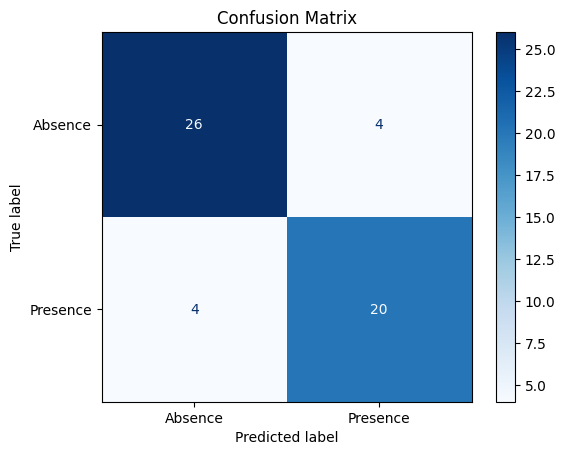

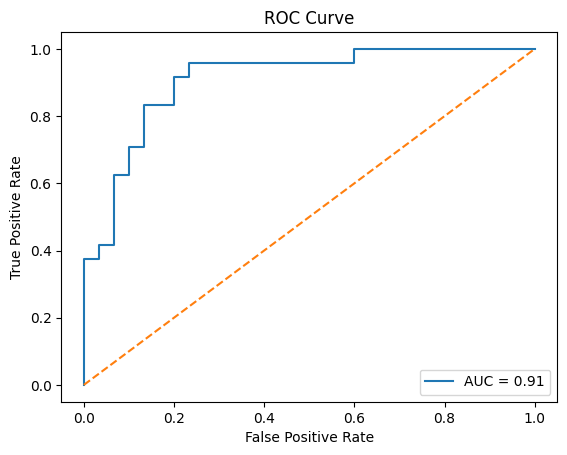

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Absence", "Presence"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
y_prob = best_model.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1], [0,1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

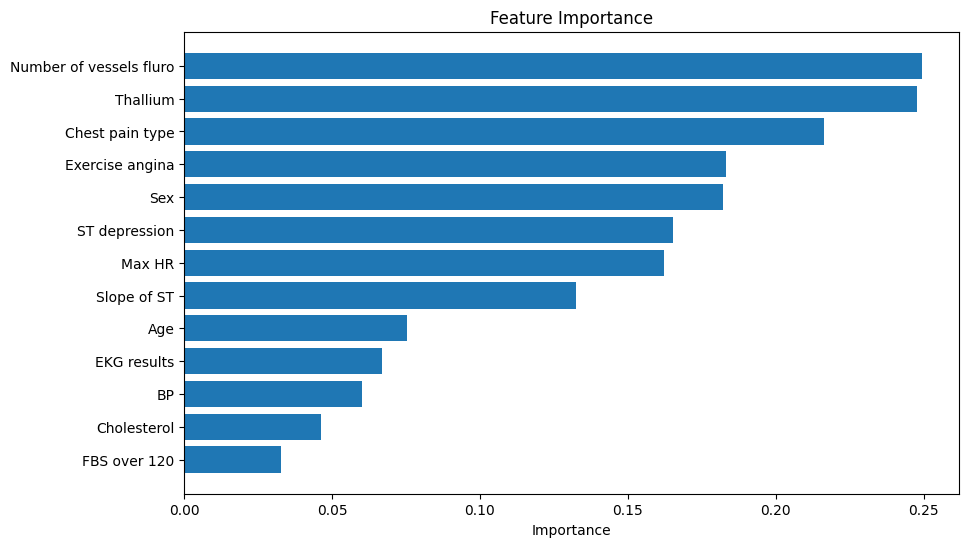

,Feature,Importance
11,Number of vessels fluro,0.249561
12,Thallium,0.247785
2,Chest pain type,0.216433
8,Exercise angina,0.183258
1,Sex,0.182234
9,ST depression,0.165207
7,Max HR,0.162249
10,Slope of ST,0.132409
0,Age,0.075219
6,EKG results,0.066837


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Get coefficients from Logistic Regression
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": abs(best_model.named_steps["model"].coef_[0])
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,6))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()

importance

In [ ]:
import joblib

joblib.dump(best_model, "heart_disease_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
# Example patient data
new_patient = pd.DataFrame([{
    "Age": 55,
    "Sex": 1,
    "Chest pain type": 3,
    "BP": 140,
    "Cholesterol": 250,
    "FBS over 120": 0,
    "EKG results": 1,
    "Max HR": 150,
    "Exercise angina": 0,
    "ST depression": 1.2,
    "Slope of ST": 2,
    "Number of vessels fluro": 0,
    "Thallium": 6
}])

prediction = best_model.predict(new_patient)

if prediction[0] == 1:
    print("Prediction: Presence of Heart Disease")
else:
    print("Prediction: Absence of Heart Disease")

Prediction: Absence of Heart Disease


In [ ]:
# # Heart Disease Prediction - Project Summary

# ## Problem Statement
# The goal of this project is to build a machine learning classification model that predicts whether a patient has heart disease based on medical attributes.

# ## Dataset
# The dataset contains 270 patient records with 13 medical features including age, blood pressure, cholesterol, chest pain type, maximum heart rate, and other clinical measurements.

# ## Models Used
# - Logistic Regression
# - Decision Tree Classifier
# - Random Forest Classifier
# - Support Vector Machine (SVM)

# ## Best Model
# The best performing model was Logistic Regression with hyperparameter tuning.

# ## Performance
# - Test Accuracy: 85%
# - Balanced precision and recall for both classes

# ## Key Features
# The most influential features were:
# - Number of vessels fluro
# - Thallium
# - Chest pain type
# - Exercise angina
# - Sex

# ## Conclusion
# The model successfully predicts heart disease presence with good accuracy. This project demonstrates a complete machine learning workflow from data preprocessing to model evaluation and prediction.